# Observed forecast errors and residual intervals

Executed research analysis on real local inputs or committed aggregate reports. Historical/validation scope is labeled explicitly. No test rescoring occurs. Use the isolated repository environment plus Jupyter, pandas and matplotlib.

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists()
os.chdir(ROOT)
for path in [ROOT, ROOT / 'src']:
    if str(path) not in sys.path: sys.path.insert(0, str(path))
FIGURES = ROOT / 'docs' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
def show_figure(fig, name):
    path = FIGURES / (name + '.png')
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(path)))
print('Executed analysis; Python', sys.version.split()[0])
print('Only aggregate outputs and figures are retained; raw rows/weights remain ignored.')


Executed analysis; Python 3.14.2
Only aggregate outputs and figures are retained; raw rows/weights remain ignored.


## Previously observed 2026 diagnostic evidence
All metrics are loaded from tracked aggregate JSON. This notebook does not run predictions, optimize parameters or tune calibration. Zero remains slightly better than the retained learned mean. Nominal coverage is an empirical diagnostic, not a guarantee under regime change.

,model,rmse
0,Prior global,0.002987
1,Retained ridge v2,0.002957
2,Zero,0.002952


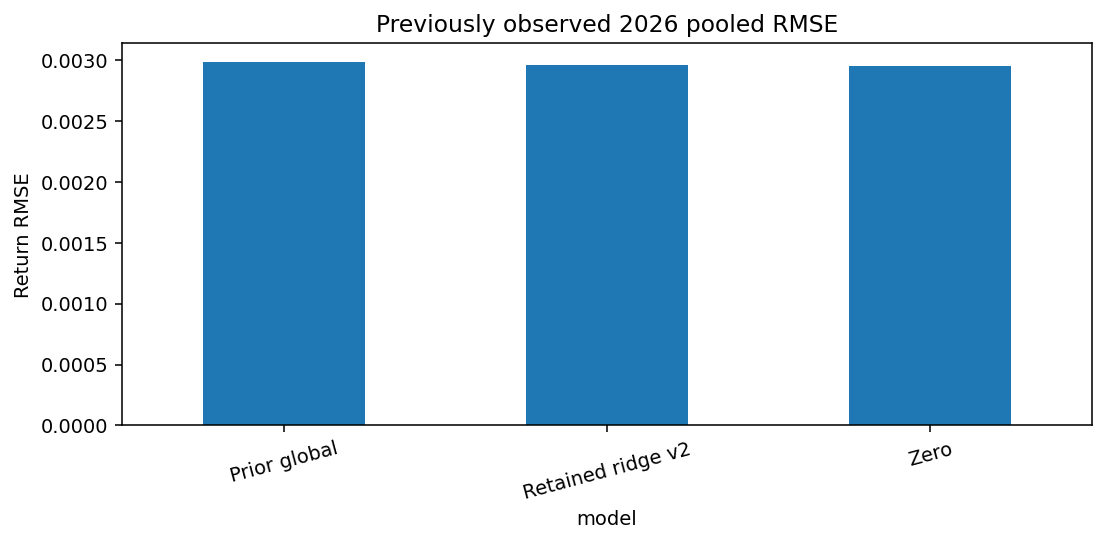

In [2]:
result=read_json('models/uncertainty-v2/results.json')
prior=read_json('models/multi-asset-v1/evaluation.json')
comparison=pd.DataFrame([{'model':'Prior global','rmse':prior['forecast_scores']['pooled']['global_rmse']},{'model':'Retained ridge v2','rmse':result['pooled_rmse']},{'model':'Zero','rmse':result['pooled_zero_rmse']}])
display(comparison)
fig,ax=plt.subplots(figsize=(8,4))
comparison.set_index('model').rmse.plot.bar(ax=ax)
ax.set(title='Previously observed 2026 pooled RMSE',ylabel='Return RMSE')
ax.tick_params(axis='x',rotation=15)
show_figure(fig,'quant_observed_point_comparison')

,asset,interval,rows,rmse,coverage,mean_width,mean_interval_score
0,FXEURCAD,volatility_normalized,194,0.002397,0.881443,0.007406,0.010598
1,FXEURCAD,constant,194,0.002397,0.963918,0.010187,0.011157
2,FXGBPCAD,volatility_normalized,194,0.002693,0.907216,0.009711,0.012163
3,FXGBPCAD,constant,194,0.002693,0.979381,0.012492,0.013111
4,FXAUDCAD,volatility_normalized,194,0.003637,0.855670,0.011123,0.016670
5,FXAUDCAD,constant,194,0.003637,0.850515,0.010422,0.015856


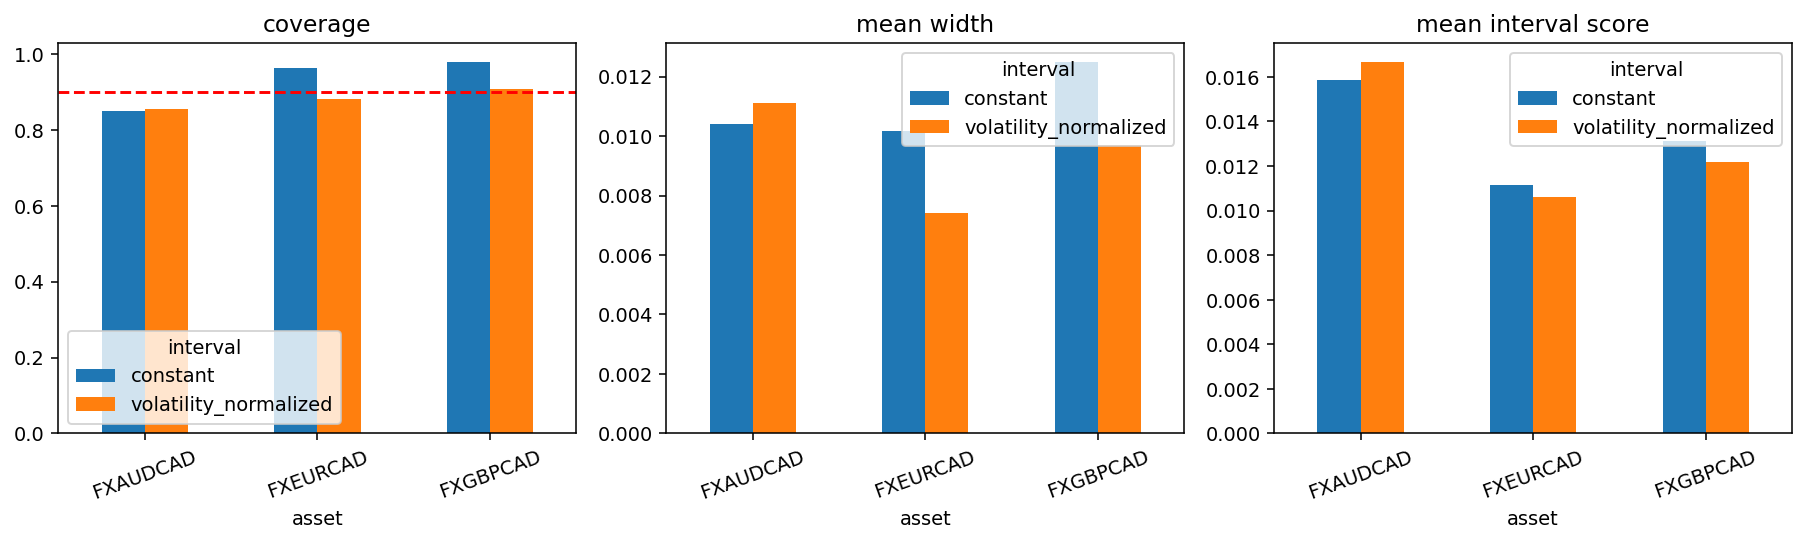

In [3]:
rows=[]
for asset,variants in result['per_asset'].items():
    for name in ['volatility_normalized','constant']:rows.append({'asset':asset,'interval':name,**variants[name]})
intervals=pd.DataFrame(rows)
display(intervals)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,metric in zip(axes,['coverage','mean_width','mean_interval_score']):
    intervals.pivot(index='asset',columns='interval',values=metric).plot.bar(ax=ax)
    ax.set(title=metric.replace('_',' '))
    ax.tick_params(axis='x',rotation=20)
axes[0].axhline(.9,color='red',linestyle='--',label='Nominal 90%')
show_figure(fig,'quant_observed_interval_diagnostics')

## Proper-score interpretation and delayed labels
Narrow intervals can under-cover; coverage alone rewards excessively wide intervals. The proper interval score penalizes both width and misses. Online rolling policies lost the 2025 prespecified comparison, so fixed calibration was retained. The queue has 588 matured labels including six bridge arrivals, 582 scored test predictions and six pending decisions; these are different cohorts.

In [4]:
paths=list(Path('models').glob('online-interval-v3/*.json'))
print('Online aggregate reports:',[str(p) for p in paths])
for p in paths:
    value=read_json(p)
    print(p.name,'top-level aggregate keys:',list(value)[:12])
print('These reports contain aggregates/hashes only; state queues and source rows remain ignored.')

Online aggregate reports: ['models\\online-interval-v3\\results.json', 'models\\online-interval-v3\\selection.json', 'models\\online-interval-v3\\verification.json']
results.json top-level aggregate keys: ['selection_sha256', 'selected_policy', 'observed_2026', 'state_verification', 'point_checkpoint_sha256', 'test_provenance', 'runtime_seconds', 'mean_model_changed', 'risk_policy_changed', 'disclosure', 'limitations']
selection.json top-level aggregate keys: ['plan_sha256', 'implementation_sha256', 'point_selection', 'diagnostic_point_spec', 'runs', 'selected_policy', 'test_used_for_selection', 'development_provenance', 'disclosure']
verification.json top-level aggregate keys: ['matched_v2_rows', 'max_delta', 'new_test_predictions_sha256', 'cli', 'state_roundtrip', 'tests_passed', 'run_implementation_sha256', 'current_source_sha256', 'post_run_noncomputational_change', 'before_state_guard_source_sha256', 'scientific_run_tests_passed', 'state_guard_audit']
These reports contain aggrega